In [7]:

import pandas as pd

DATA_PATH = "real-estate_dataset_addis-ababa_v1.csv"

training_df = pd.read_csv(DATA_PATH, low_memory=False)

# 1. Basic structure
print("\n1. DATASET STRUCTURE")
print("Shape:", training_df.shape)
print("\nData types:")
print(training_df.dtypes)

# 2. Target validation
# Use price as the initial target.
target = "price"

print("\n2. TARGET VALIDATION")
print("Missing targets:", training_df[target].isna().sum())
print("Non-positive targets:", (training_df[target] <= 0).sum())

print("\nTarget statistics:")
print(training_df[target].describe())

# 3. Provider distribution
print("\n3. RECORDS BY PROVIDER")
print(training_df["provider"].value_counts(dropna=False))

print("\nPRICE STATISTICS BY PROVIDER")
print(
    training_df.groupby("provider")[target]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("count", ascending=False)
    .round(2)
)

# 4. Price type audit
print("\n4. PRICE TYPE DISTRIBUTION")
print(training_df["price_type"].value_counts(dropna=False))

print("\nPRICE SUMMARY BY PRICE TYPE")
print(
    training_df.groupby("price_type", dropna=False)[target]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

# 5. Property size audit
print("\n5. PROPERTY SIZE SUMMARY")
print(training_df["size_sqm"].describe())

print("\nPROPERTY SIZE IMPUTATION FLAGS")
print(training_df["size_sqm_is_imputed"].value_counts(dropna=False))

print("\nPROPERTY SIZE BY PROPERTY TYPE")
print(
    training_df.groupby("property_type", dropna=False)["size_sqm"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

# 6. Missing values
print("\n6. MISSING VALUES")
missing = training_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing if not missing.empty else "No missing values.")

# 7. Potentially extreme prices
print("\n7. HIGHEST 20 PRICES")

columns_to_show = [
    "provider",
    "listing_type",
    "property_type",
    "title",
    "subcity",
    "price",
    "price_adj",
    "size_sqm",
    "num_bedrooms",
    "num_bathrooms"
]

print(
    training_df.nlargest(20, target)[columns_to_show]
    .to_string(index=False)
)

# 8. Very low prices
print("\n8. LOWEST 20 PRICES")

print(
    training_df.nsmallest(20, target)[columns_to_show]
    .to_string(index=False)
)

# 9. Duplicate identifier check
print("\n9. DUPLICATE IDENTIFIER CHECK")
print("Duplicate id:", training_df["id"].duplicated().sum())

print(
    "Duplicate provider + id:",
    training_df.duplicated(["provider", "id"]).sum()
)

# 10. Listing type distribution
print("\n10. LISTING TYPE DISTRIBUTION")
print(training_df["listing_type"].value_counts(dropna=False))

print("\nAUDIT COMPLETE — NO RECORDS WERE MODIFIED.")



1. DATASET STRUCTURE
Shape: (85400, 50)

Data types:
id                                    str
provider                              str
listing_type                          str
property_type                         str
price                             float64
price_adj                         float64
price_sqm                         float64
price_adj_sqm                     float64
price_type                            str
size_sqm                          float64
plot_size                         float64
size_sqm_is_imputed                   str
address                               str
address_extracted                     str
address_main                          str
address_alt                           str
unique_address_grp                float64
place_name                            str
place_id                              str
subcity                               str
lng                               float64
lat                               float64
is_lng_lat_sampled    

EXPLORATORY DATA ANALYSIS

1. TARGET DISTRIBUTION
count    8.540000e+04
mean     9.902915e+06
std      1.305990e+07
min      1.500000e+03
25%      2.100000e+06
50%      5.900000e+06
75%      1.300000e+07
max      2.300000e+08
Name: price, dtype: float64

Skewness: 3.6
Kurtosis: 22.415


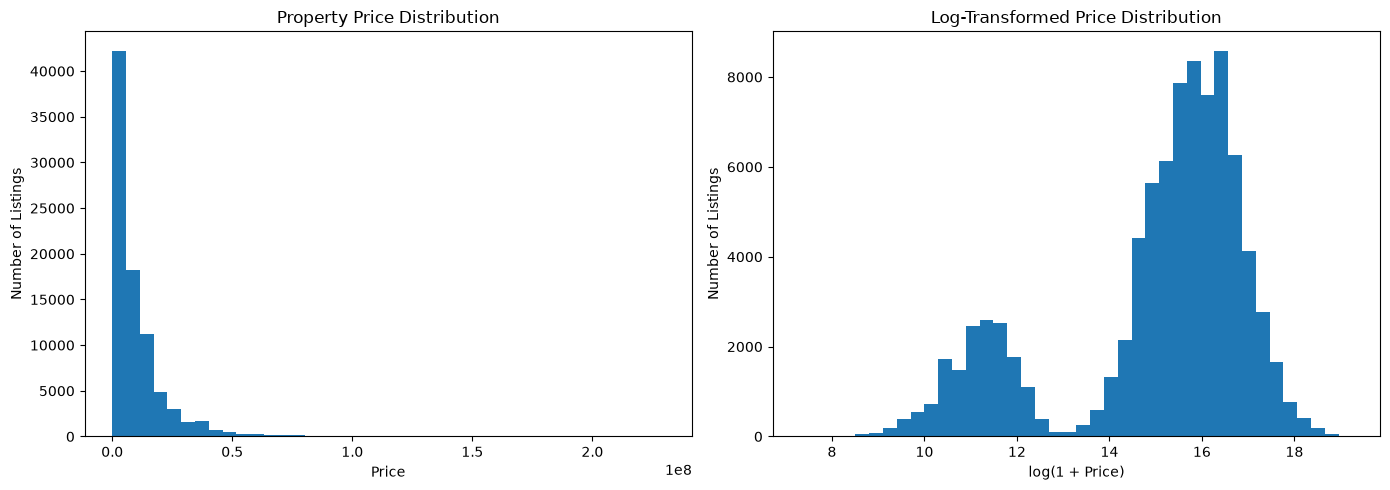


2. PRICE BY PROVIDER
                        count      median         mean          std
provider                                                           
afrotie                 17546   7100000.0  11459344.94  13540235.46
beten                     867  19500000.0  24657305.71  19994298.15
engocha                  1568   9200000.0  10951545.49  10179015.60
ethiopianproperties        43   8000000.0   9054550.62   8237300.67
ethiopiapropertycentre   2427  10900000.0  11870740.92  10410449.96
jiji                     7074   8512784.5  14378697.20  18685011.85
livingethio               639   4100000.0  11390507.87  17486724.29
loozap                  51332   4900000.0   7951599.74  10605974.59
qefira                   2682  13000000.0  17245786.60  17908933.70
realethio                 858    150000.0  11663350.70  23705110.55
zegebeya                  364   4600000.0   9528546.65  13529227.34


<Figure size 1200x600 with 0 Axes>

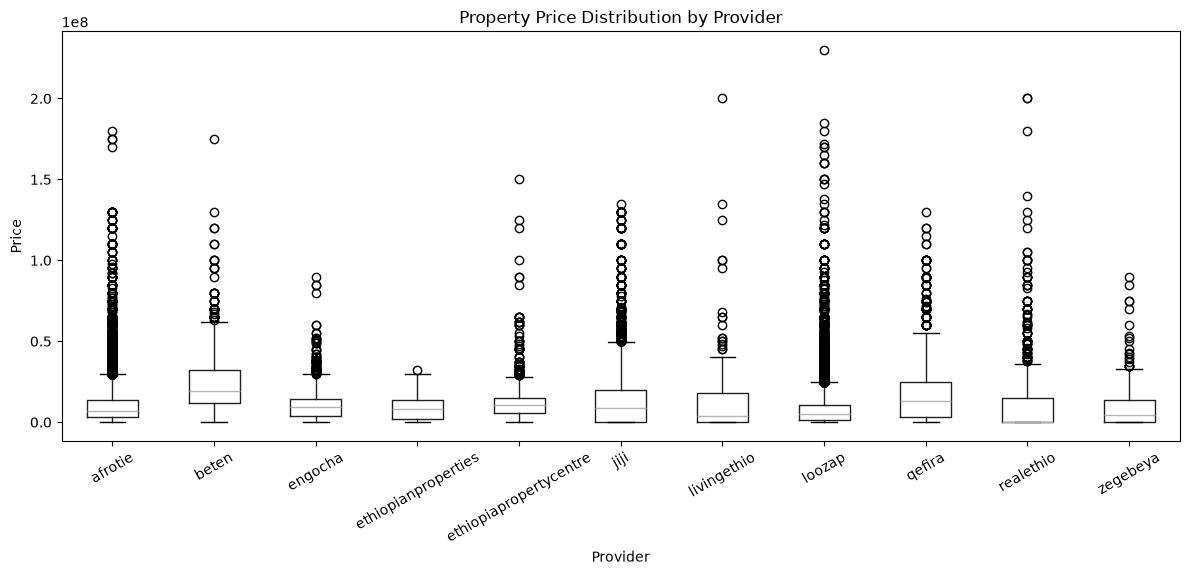


3. PROPERTY TYPE DISTRIBUTION
property_type
apartment     38241
house         37938
land           5022
commercial     2844
other           899
building        456
Name: count, dtype: int64

Price by property type:
               count      median         mean
property_type                                
apartment      38241   4300000.0   6229305.66
house          37938   7875004.0  12583369.07
land            5022   9000000.0  14139022.57
commercial      2844   4360400.0  11671838.27
other            899   4700000.0   7552495.56
building         456  28000000.0  41920181.87

4. NUMERICAL FEATURE RELATIONSHIPS

Correlation with target:
price                 1.000
size_sqm              0.424
num_bathrooms         0.385
num_bedrooms         -0.003
plot_size            -0.006
num_images           -0.015
dist_meskel_square   -0.018
dist_piassa          -0.031
dist_arat_kilo       -0.034
Name: price, dtype: float64


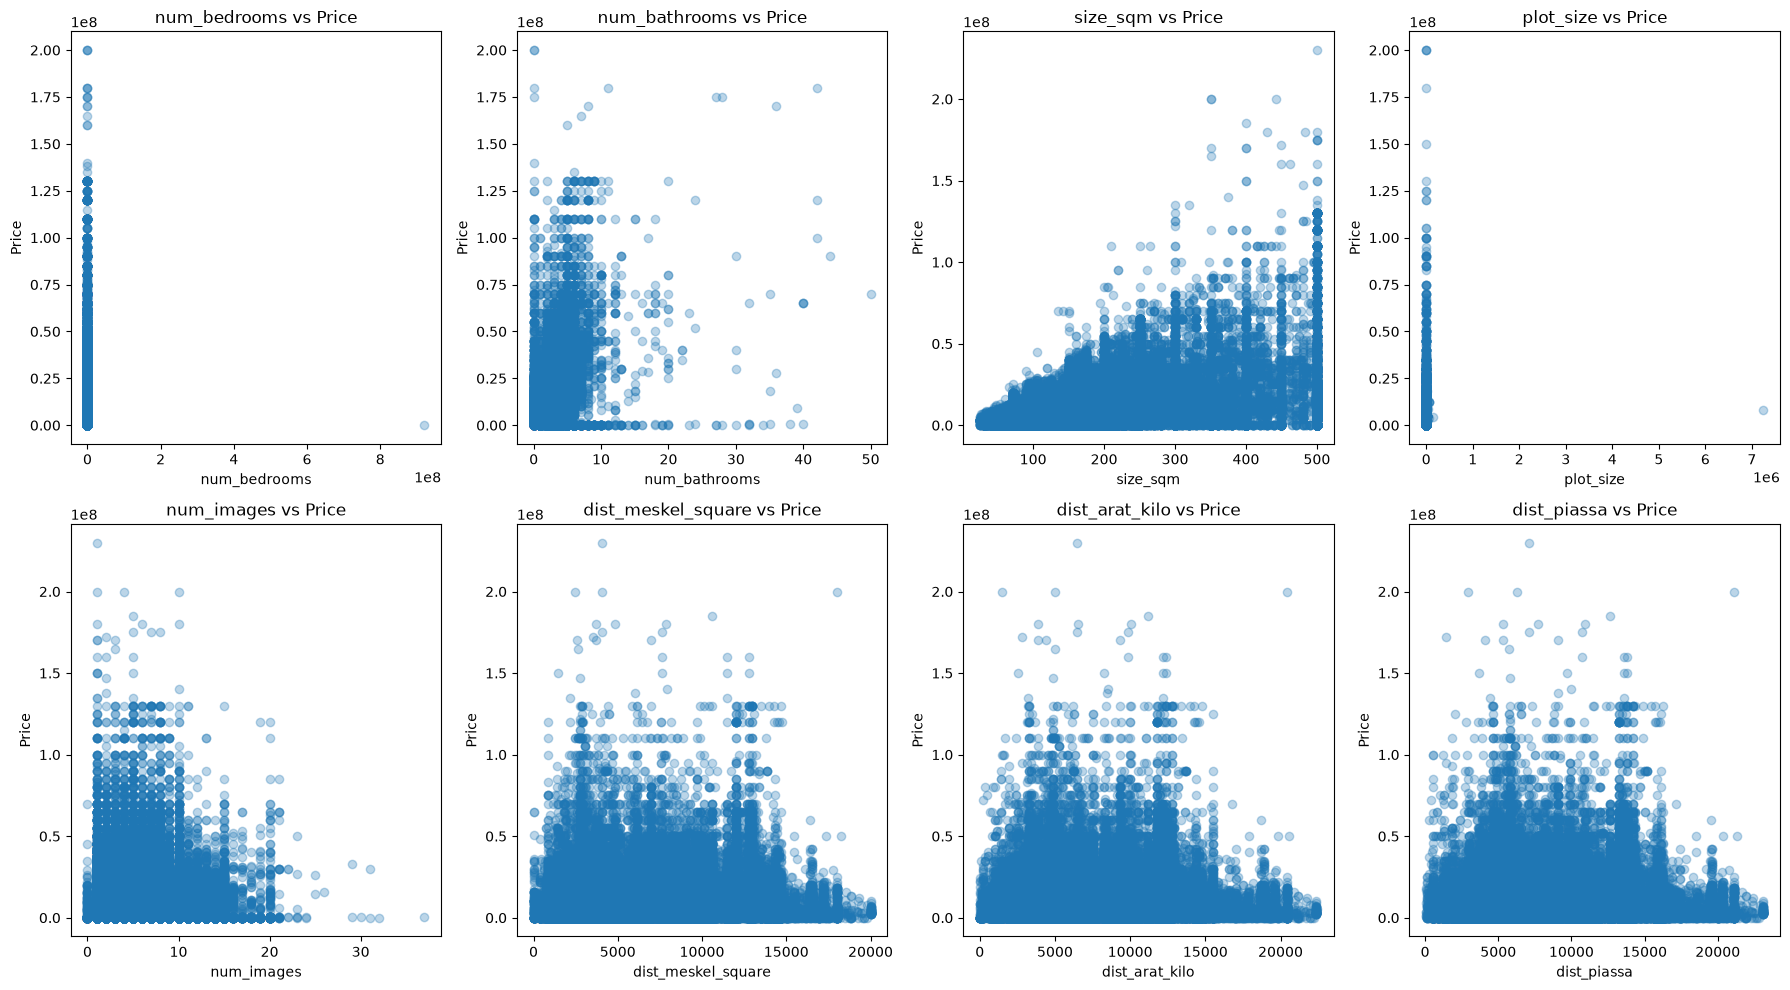


6. PRICE TYPE DISTRIBUTION
price_type
other         60567
fixed         15113
negotiable     9720
Name: count, dtype: int64

Price statistics by price type:
            count     median         mean     min          max
price_type                                                    
fixed       15113  5600000.0   9725932.33  1500.0  170000000.0
negotiable   9720  7600000.0  12885022.10  6000.0  200000000.0
other       60567  5600000.0   9468497.36  2200.0  230000000.0

8. CATEGORICAL FEATURE CARDINALITY
listing_type: 2 unique values
property_type: 6 unique values
price_type: 3 unique values
subcity: 11 unique values
condition: 3 unique values
furnishing: 4 unique values
pets: 2 unique values
garden: 2 unique values
parking: 2 unique values
kitchen: 2 unique values
elevator: 2 unique values
balcony: 2 unique values
water: 2 unique values
power: 2 unique values


In [10]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = training_df.copy()

target = "price"

print("EXPLORATORY DATA ANALYSIS")

print("\n1. TARGET DISTRIBUTION")

target_data = df[target].dropna()
target_data = target_data[target_data > 0]

print(target_data.describe().round(2))

print("\nSkewness:", round(target_data.skew(), 3))
print("Kurtosis:", round(target_data.kurtosis(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(target_data, bins=40)
axes[0].set_title("Property Price Distribution")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Number of Listings")

axes[1].hist(np.log1p(target_data), bins=40)
axes[1].set_title("Log-Transformed Price Distribution")
axes[1].set_xlabel("log(1 + Price)")
axes[1].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()


print("\n2. PRICE BY PROVIDER")

provider_stats = (
    df.groupby("provider")[target]
    .agg(["count", "median", "mean", "std"])
    .round(2)
)

print(provider_stats)

plt.figure(figsize=(12, 6))

df.boxplot(
    column=target,
    by="provider",
    grid=False,
    rot=30,
    figsize=(12, 6)
)

plt.title("Property Price Distribution by Provider")
plt.suptitle("")
plt.xlabel("Provider")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


print("\n3. PROPERTY TYPE DISTRIBUTION")

print(df["property_type"].value_counts(dropna=False).head(20))

property_stats = (
    df.groupby("property_type", dropna=False)[target]
    .agg(["count", "median", "mean"])
    .sort_values("count", ascending=False)
)

print("\nPrice by property type:")
print(property_stats.head(20).round(2))


print("\n4. NUMERICAL FEATURE RELATIONSHIPS")

numerical_features = [
    "num_bedrooms",
    "num_bathrooms",
    "size_sqm",
    "plot_size",
    "num_images",
    "dist_meskel_square",
    "dist_arat_kilo",
    "dist_piassa"
]

correlation_data = df[numerical_features + [target]]

print("\nCorrelation with target:")
print(
    correlation_data.corr(numeric_only=True)[target]
    .sort_values(ascending=False)
    .round(3)
)

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for ax, feature in zip(axes, numerical_features):
    valid = df[[feature, target]].dropna()
    valid = valid[(valid[feature] >= 0) & (valid[target] > 0)]

    ax.scatter(
        valid[feature],
        valid[target],
        alpha=0.3
    )

    ax.set_title(f"{feature} vs Price")
    ax.set_xlabel(feature)
    ax.set_ylabel("Price")

plt.tight_layout()
plt.show()

print("\n6. PRICE TYPE DISTRIBUTION")

print(df["price_type"].value_counts(dropna=False))

print("\nPrice statistics by price type:")

print(
    df.groupby("price_type", dropna=False)[target]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

print("\n8. CATEGORICAL FEATURE CARDINALITY")

categorical_features = [
    "listing_type",
    "property_type",
    "price_type",
    "subcity",
    "condition",
    "furnishing",
    "pets",
    "garden",
    "parking",
    "kitchen",
    "elevator",
    "balcony",
    "water",
    "power"
]

for feature in categorical_features:
    print(
        f"{feature}: "
        f"{df[feature].nunique(dropna=True)} unique values"
    )



In [12]:

import pandas as pd
import numpy as np

# feature-quality 

df = training_df.copy()

# 1. Price types by provider
print("\n1. PRICE TYPES BY PROVIDER")

print(pd.crosstab(
    df["provider"],
    df["price_type"],
    margins=True,
    dropna=False
))

# 3. Categorical cardinality
categorical = [
    "property_type",
    "subcity",
    "furnishing",
    "condition"
]

print("\n3. CATEGORICAL CARDINALITY")

for col in categorical:
    print(f"\n{col}: {df[col].nunique(dropna=True)} unique values")
    print(df[col].value_counts(dropna=False).head(15))

# 4. Low-price listings for pricing-unit review
print("\n4. LISTINGS WITH PRICE <= 5,000")

low_price_columns = [
    "provider",
    "listing_type",
    "id",
    "title",
    "price",
    "price_adj",
    "price_type",
    "size_sqm",
    "num_bedrooms"
]

print(
    df[df["price"] <= 5000][low_price_columns]
    .sort_values("price")
    .to_string(index=False)
)

# 5. Property size quality
print("\n5. PROPERTY SIZE QUALITY")

print("Missing sizes:", df["size_sqm"].isna().sum())
print("Zero or negative sizes:", (df["size_sqm"] <= 0).sum())

print("\nProperty size statistics:")
print(df["size_sqm"].describe().round(2))

print("\nProperty size imputation flags:")
print(df["size_sqm_is_imputed"].value_counts(dropna=False))



1. PRICE TYPES BY PROVIDER
price_type              fixed  negotiable  other    All
provider                                               
afrotie                  4623        1829  11094  17546
beten                     113         169    585    867
engocha                   854         289    425   1568
ethiopianproperties        14          20      9     43
ethiopiapropertycentre    677          64   1686   2427
jiji                      439         246   6389   7074
livingethio                 2           2    635    639
loozap                   7125        6196  38011  51332
qefira                   1015         439   1228   2682
realethio                 165         453    240    858
zegebeya                   86          13    265    364
All                     15113        9720  60567  85400

3. CATEGORICAL CARDINALITY

property_type: 6 unique values
property_type
apartment     38241
house         37938
land           5022
commercial     2844
other           899
building      

In [16]:

import pandas as pd
from sklearn.model_selection import train_test_split

df = training_df.copy().reset_index(drop=True)

df = df[
    df["listing_type"]
    .astype("string")
    .str.contains("rent", case=False, na=False)
].copy()

if df.empty:
    raise ValueError("No rental listings found. Check listing_type.")

feature_columns = [
    "property_type",
    "subcity",
    "num_bedrooms",
    "num_bathrooms",
    "condition"
]

target_column = "price"

df = df[
    df[target_column].notna() &
    (df[target_column] > 0)
].copy()

# temporary target bins for stratification
df["price_stratum"] = pd.qcut(
    df[target_column],
    q=10,
    labels=False,
    duplicates="drop"
)

# Split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["price_stratum"]
)

# Split temporary data: 15% validation, 15% test
validation_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["price_stratum"]
)

# Separate features and target
X_train = train_df[feature_columns].copy()
y_train = train_df[target_column].copy()

X_validation = validation_df[feature_columns].copy()
y_validation = validation_df[target_column].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df[target_column].copy()

# Display dimensions
print("TRAIN / VALIDATION / TEST SPLIT")

print("Training:", len(X_train))
print("Validation:", len(X_validation))
print("Test:", len(X_test))
print("Total:", len(X_train) + len(X_validation) + len(X_test))

print("\nFEATURE DIMENSIONS")
print("X_train:", X_train.shape)
print("X_validation:", X_validation.shape)
print("X_test:", X_test.shape)



TRAIN / VALIDATION / TEST SPLIT
Training: 11299
Validation: 2421
Test: 2422
Total: 16142

FEATURE DIMENSIONS
X_train: (11299, 5)
X_validation: (2421, 5)
X_test: (2422, 5)


In [18]:
import pandas as pd
import numpy as np
import os
import sklearn

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# 1. Prepare features
categorical_features = ["property_type", "subcity", "condition"]
numerical_features = ["num_bedrooms", "num_bathrooms"]
feature_columns = categorical_features + numerical_features

def prepare_features(X):
    X = X[feature_columns].copy()
    X[categorical_features] = X[categorical_features].apply(
        lambda col: col.astype("string").str.strip().str.lower()
    ).astype(object).where(X[categorical_features].notna(), np.nan)
    X[numerical_features] = X[numerical_features].apply(
        pd.to_numeric, errors="coerce"
    )
    return X

X_train_prepared = prepare_features(X_train)
X_validation_prepared = prepare_features(X_validation)

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=5))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Define models
algorithms = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=42)
}

# Train and evaluate
results, trained_models = [], {}

for name, algorithm in algorithms.items():
    for mode in ["original", "log"]:
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm)
        ])

        model = (
            TransformedTargetRegressor(
                regressor=pipeline, func=np.log1p, inverse_func=np.expm1
            ) if mode == "log" else pipeline
        )

        model.fit(X_train_prepared, y_train)
        predictions = model.predict(X_validation_prepared)

        mae = mean_absolute_error(y_validation, predictions)
        mse = mean_squared_error(y_validation, predictions)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_validation, predictions)

        experiment = f"{name} ({mode})"
        results.append({
            "model": experiment, "MAE": mae, "MSE": mse,
            "RMSE": rmse, "R2": r2
        })
        trained_models[experiment] = model

        print(f"{experiment}: MAE={mae:,.2f}, RMSE={rmse:,.2f}, R2={r2:.4f}")

# Compare results
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

print("\nVALIDATION RESULTS")
print(results_df.round(3).to_string(index=False))



Linear Regression (original): MAE=39,485.54, RMSE=53,273.79, R2=0.2814
Linear Regression (log): MAE=43,228.58, RMSE=208,933.02, R2=-10.0530
Decision Tree (original): MAE=37,177.72, RMSE=50,961.13, R2=0.3424
Decision Tree (log): MAE=36,679.82, RMSE=52,639.47, R2=0.2984
Random Forest (original): MAE=36,648.52, RMSE=50,694.09, R2=0.3493
Random Forest (log): MAE=35,972.10, RMSE=51,716.38, R2=0.3228
Gradient Boosting (original): MAE=37,177.27, RMSE=50,270.36, R2=0.3601
Gradient Boosting (log): MAE=36,633.00, RMSE=52,589.08, R2=0.2997

VALIDATION RESULTS
                       model       MAE          MSE       RMSE      R2
Gradient Boosting (original) 37177.272 2.527109e+09  50270.364   0.360
    Random Forest (original) 36648.521 2.569891e+09  50694.091   0.349
    Decision Tree (original) 37177.721 2.597037e+09  50961.129   0.342
         Random Forest (log) 35972.102 2.674584e+09  51716.378   0.323
     Gradient Boosting (log) 36633.003 2.765612e+09  52589.083   0.300
         Decision T

In [19]:
diagnostics = []

for name, model in trained_models.items():
    train_pred = model.predict(X_train_prepared)
    val_pred = model.predict(X_validation_prepared)

    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    val_rmse = np.sqrt(mean_squared_error(y_validation, val_pred))

    diagnostics.append({
        "Model": name,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Validation MAE": mean_absolute_error(y_validation, val_pred),
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse,
        "RMSE Gap": val_rmse - train_rmse,
        "Train R2": r2_score(y_train, train_pred),
        "Validation R2": r2_score(y_validation, val_pred)
    })

diagnostics_df = pd.DataFrame(diagnostics).sort_values("Validation RMSE").reset_index(drop=True)

print("TRAINING VS VALIDATION PERFORMANCE")
print(diagnostics_df.round(3).to_string(index=False))

TRAINING VS VALIDATION PERFORMANCE
                       Model  Train MAE  Validation MAE  Train RMSE  Validation RMSE    RMSE Gap  Train R2  Validation R2
Gradient Boosting (original)  38077.823       37177.272   51071.166        50270.364    -800.802     0.371          0.360
    Random Forest (original)  33697.822       36648.521   46082.297        50694.091    4611.794     0.488          0.349
    Decision Tree (original)  36823.606       37177.721   50010.763        50961.129     950.366     0.397          0.342
         Random Forest (log)  33500.397       35972.102   48443.072        51716.378    3273.305     0.434          0.323
     Gradient Boosting (log)  37695.026       36633.003   54022.962        52589.083   -1433.879     0.296          0.300
         Decision Tree (log)  36297.697       36679.822   52268.595        52639.472     370.877     0.341          0.298
Linear Regression (original)  40923.331       39485.540   55212.286        53273.794   -1938.492     0.265     

In [21]:
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.ensemble import (
    GradientBoostingRegressor,
    RandomForestRegressor
)
from sklearn.pipeline import Pipeline

# Five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Gradient Boosting search space
gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", GradientBoostingRegressor(
        random_state=42
    ))
])

gb_parameters = {
    "regressor__n_estimators": [100, 150, 200, 300],
    "regressor__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "regressor__max_depth": [2, 3, 4],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [2, 5, 10],
    "regressor__subsample": [0.7, 0.85, 1.0],
    "regressor__max_features": [None, "sqrt", 0.8]
}

# Random Forest search space
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

rf_parameters = {
    "regressor__n_estimators": [200, 300, 500],
    "regressor__max_depth": [None, 10, 15, 20],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [2, 4, 6],
    "regressor__max_features": [1.0, "sqrt", 0.8]
}


In [22]:
search_spaces = {
    "Gradient Boosting": (
        gb_pipeline,
        gb_parameters
    ),
    "Random Forest": (
        rf_pipeline,
        rf_parameters
    )
}

searches = {}
tuning_results = []

for model_name, (pipeline, parameters) in search_spaces.items():

    print("\n" + "=" * 70)
    print(f"TUNING: {model_name}")
    print("=" * 70)

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parameters,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        random_state=42,
        verbose=1,
        return_train_score=True
    )

    # Only training data is used here.
    search.fit(X_train_prepared, y_train)

    searches[model_name] = search

    best_cv_rmse = -search.best_score_

    tuning_results.append({
        "Model": model_name,
        "Best CV RMSE": best_cv_rmse,
        "Best Parameters": search.best_params_
    })

    print("\nBest cross-validation RMSE:", round(best_cv_rmse, 2))
    print("\nBest parameters:")
    print(search.best_params_)

tuning_results_df = pd.DataFrame(tuning_results)

print("\n" + "=" * 70)
print("HYPERPARAMETER TUNING SUMMARY")
print("=" * 70)

print(
    tuning_results_df[
        ["Model", "Best CV RMSE"]
    ].round(2).to_string(index=False)
)


TUNING: Gradient Boosting
Fitting 5 folds for each of 20 candidates, totalling 100 fits



Best cross-validation RMSE: 51971.36

Best parameters:
{'regressor__subsample': 0.7, 'regressor__n_estimators': 200, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 2, 'regressor__max_features': None, 'regressor__max_depth': 4, 'regressor__learning_rate': 0.05}

TUNING: Random Forest
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best cross-validation RMSE: 51546.2

Best parameters:
{'regressor__n_estimators': 200, 'regressor__min_samples_split': 5, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.8, 'regressor__max_depth': 15}

HYPERPARAMETER TUNING SUMMARY
            Model  Best CV RMSE
Gradient Boosting      51971.36
    Random Forest      51546.20


In [23]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

tuned_validation_results = []
tuned_models = {}

for model_name, search in searches.items():

    best_model = search.best_estimator_
    tuned_models[model_name] = best_model

    # Predict training and validation data
    train_predictions = best_model.predict(X_train_prepared)
    validation_predictions = best_model.predict(X_validation_prepared)

    # Training metrics
    train_rmse = np.sqrt(
        mean_squared_error(y_train, train_predictions)
    )

    # Validation metrics
    mae = mean_absolute_error(
        y_validation, validation_predictions
    )
    mse = mean_squared_error(
        y_validation, validation_predictions
    )
    rmse = np.sqrt(mse)
    r2 = r2_score(
        y_validation, validation_predictions
    )

    tuned_validation_results.append({
        "Model": model_name,
        "CV RMSE": -search.best_score_,
        "Train RMSE": train_rmse,
        "Validation MAE": mae,
        "Validation MSE": mse,
        "Validation RMSE": rmse,
        "Validation R2": r2,
        "RMSE Gap": rmse - train_rmse
    })

tuned_validation_df = pd.DataFrame(
    tuned_validation_results
).sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("=" * 110)
print("TUNED MODEL VALIDATION RESULTS")
print("=" * 110)

print(tuned_validation_df.round(3).to_string(index=False))

tuned_validation_df.to_csv(
    "data/processed/tuned_model_validation_results.csv",
    index=False
)

TUNED MODEL VALIDATION RESULTS
            Model   CV RMSE  Train RMSE  Validation MAE  Validation MSE  Validation RMSE  Validation R2  RMSE Gap
Gradient Boosting 51971.361   49505.410       36704.232    2.498498e+09        49984.976          0.367   479.566
    Random Forest 51546.196   46659.733       36297.114    2.500526e+09        50005.262          0.367  3345.529


In [24]:
baseline_comparison = results_df[
    ["model", "MAE", "RMSE", "R2"]
].copy()

baseline_comparison["Experiment"] = "Baseline"
baseline_comparison = baseline_comparison.rename(
    columns={
        "model": "Model",
        "MAE": "Validation MAE",
        "RMSE": "Validation RMSE",
        "R2": "Validation R2"
    }
)

tuned_comparison = tuned_validation_df[
    ["Model", "Validation MAE", "Validation RMSE", "Validation R2"]
].copy()

tuned_comparison["Experiment"] = "Tuned"

combined_comparison = pd.concat(
    [baseline_comparison, tuned_comparison],
    ignore_index=True
)

combined_comparison = combined_comparison.sort_values(
    "Validation RMSE"
).reset_index(drop=True)

print("=" * 100)
print("BASELINE VS TUNED MODEL COMPARISON")
print("=" * 100)

print(combined_comparison.round(3).to_string(index=False))

combined_comparison.to_csv(
    "data/processed/baseline_vs_tuned_comparison.csv",
    index=False
)

BASELINE VS TUNED MODEL COMPARISON
                       Model  Validation MAE  Validation RMSE  Validation R2 Experiment
           Gradient Boosting       36704.232        49984.976          0.367      Tuned
               Random Forest       36297.114        50005.262          0.367      Tuned
Gradient Boosting (original)       37177.272        50270.364          0.360   Baseline
    Random Forest (original)       36648.521        50694.091          0.349   Baseline
    Decision Tree (original)       37177.721        50961.129          0.342   Baseline
         Random Forest (log)       35972.102        51716.378          0.323   Baseline
     Gradient Boosting (log)       36633.003        52589.083          0.300   Baseline
         Decision Tree (log)       36679.822        52639.472          0.298   Baseline
Linear Regression (original)       39485.540        53273.794          0.281   Baseline
     Linear Regression (log)       43228.581       208933.023        -10.053   Baseli

In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

selected_model = trained_models["Gradient Boosting (original)"]

validation_predictions = selected_model.predict(
    X_validation_prepared
)

residuals = y_validation.to_numpy() - validation_predictions

residual_df = pd.DataFrame({
    "actual_rent": y_validation.to_numpy(),
    "predicted_rent": validation_predictions,
    "residual": residuals,
    "absolute_error": np.abs(residuals)
})

print("VALIDATION RESIDUAL SUMMARY")
print("=" * 60)

print(residual_df[
    ["actual_rent", "predicted_rent", "residual", "absolute_error"]
].describe().round(2))

print("\nNegative predictions:", (validation_predictions < 0).sum())
print("Mean residual:", round(residuals.mean(), 2))
print("Median residual:", round(np.median(residuals), 2))

VALIDATION RESIDUAL SUMMARY
       actual_rent  predicted_rent   residual  absolute_error
count      2421.00         2421.00    2421.00         2421.00
mean      90165.84        90314.62    -148.77        37177.27
std       62857.51        34444.44   50280.53        33844.25
min        2750.00        24469.25 -175233.31           28.48
25%       45000.00        70700.98  -31781.09        14642.72
50%       77000.00        85631.03   -9165.51        29299.02
75%      120000.00       108858.26   24246.01        50264.45
max      540000.00       381717.15  382434.94       382434.94

Negative predictions: 0
Mean residual: -148.77
Median residual: -9165.51


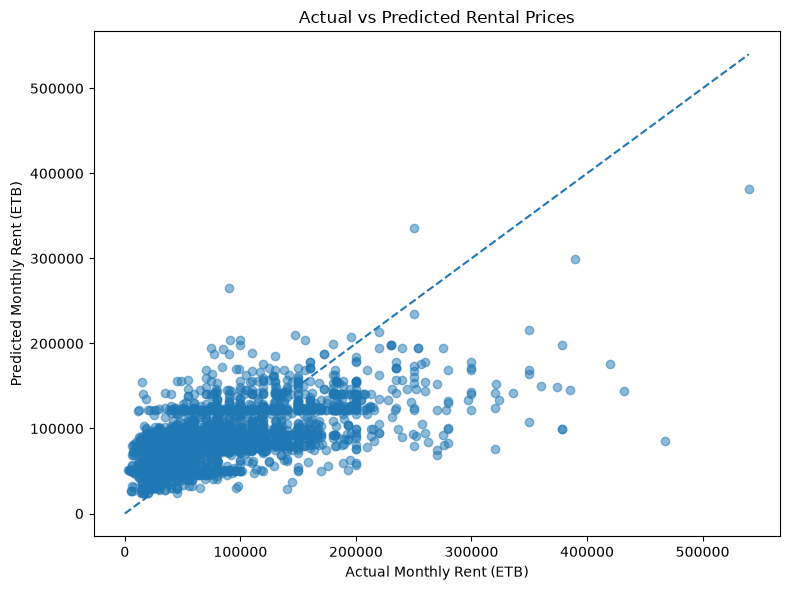

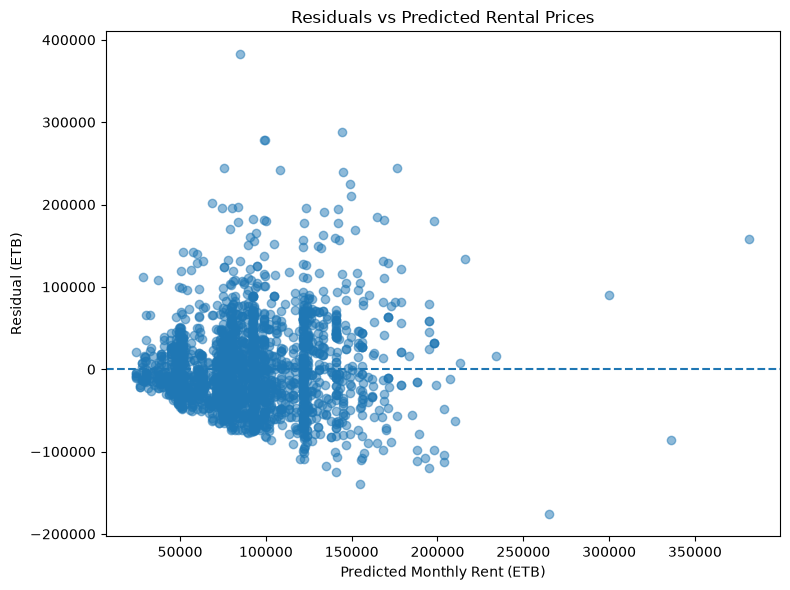

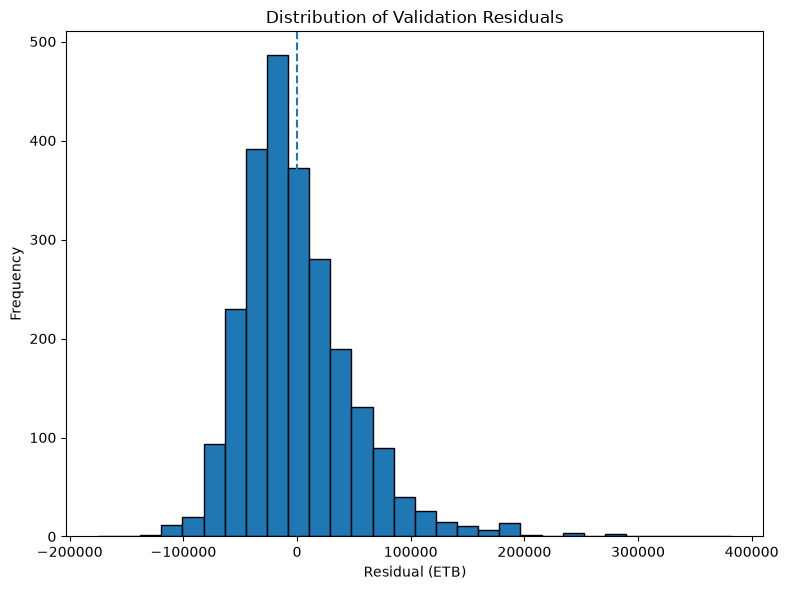

In [26]:
# Plot 1: Actual vs predicted rent
plt.figure(figsize=(8, 6))

plt.scatter(
    residual_df["actual_rent"],
    residual_df["predicted_rent"],
    alpha=0.5
)

max_value = max(
    residual_df["actual_rent"].max(),
    residual_df["predicted_rent"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.xlabel("Actual Monthly Rent (ETB)")
plt.ylabel("Predicted Monthly Rent (ETB)")
plt.title("Actual vs Predicted Rental Prices")
plt.tight_layout()
plt.show()


# Plot 2: Residuals vs predicted rent
plt.figure(figsize=(8, 6))

plt.scatter(
    residual_df["predicted_rent"],
    residual_df["residual"],
    alpha=0.5
)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Monthly Rent (ETB)")
plt.ylabel("Residual (ETB)")
plt.title("Residuals vs Predicted Rental Prices")
plt.tight_layout()
plt.show()


# Plot 3: Residual distribution
plt.figure(figsize=(8, 6))

plt.hist(
    residual_df["residual"],
    bins=30,
    edgecolor="black"
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Residual (ETB)")
plt.ylabel("Frequency")
plt.title("Distribution of Validation Residuals")
plt.tight_layout()
plt.show()

In [27]:
residual_df["rent_group"] = pd.qcut(
    residual_df["actual_rent"],
    q=5,
    duplicates="drop"
)

error_by_rent = residual_df.groupby(
    "rent_group",
    observed=True
).agg(
    listing_count=("actual_rent", "count"),
    mean_actual_rent=("actual_rent", "mean"),
    mean_predicted_rent=("predicted_rent", "mean"),
    MAE=("absolute_error", "mean"),
    mean_residual=("residual", "mean")
).reset_index()

print("=" * 100)
print("MODEL ERROR BY ACTUAL RENT RANGE")
print("=" * 100)

print(error_by_rent.round(2).to_string(index=False))

MODEL ERROR BY ACTUAL RENT RANGE
          rent_group  listing_count  mean_actual_rent  mean_predicted_rent      MAE  mean_residual
 (2749.999, 38000.0]            487          24364.14             63086.88 38795.66      -38722.75
  (38000.0, 60000.0]            483          50344.01             78714.28 30642.06      -28370.27
  (60000.0, 90000.0]            500          76883.32             88306.19 21824.90      -11422.87
 (90000.0, 135000.0]            481         112209.55            101150.31 24506.29       11059.23
(135000.0, 540000.0]            470         190841.62            121495.70 71516.17       69345.92


In [28]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import joblib
import os
import numpy as np
import pandas as pd

# Prepare the untouched test features
X_test_prepared = prepare_features(X_test)

# Selected model: original Gradient Boosting
final_model = trained_models["Gradient Boosting (original)"]

# Predict test data
test_predictions = final_model.predict(X_test_prepared)

# Calculate test metrics
test_mae = mean_absolute_error(y_test, test_predictions)
test_mse = mean_squared_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_predictions)

# Compare against a simple mean-prediction baseline
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train_prepared, y_train)

dummy_predictions = dummy_model.predict(X_test_prepared)

dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(
    mean_squared_error(y_test, dummy_predictions)
)
dummy_r2 = r2_score(y_test, dummy_predictions)

# Print results
print("=" * 75)
print("FINAL TEST SET EVALUATION")
print("=" * 75)

print(f"Test observations: {len(y_test)}")
print(f"MAE:  {test_mae:,.2f} ETB")
print(f"MSE:  {test_mse:,.2f} ETB²")
print(f"RMSE: {test_rmse:,.2f} ETB")
print(f"R²:   {test_r2:.4f}")

print("\n" + "=" * 75)
print("COMPARISON WITH MEAN-PREDICTION BASELINE")
print("=" * 75)

print(f"Dummy MAE:  {dummy_mae:,.2f} ETB")
print(f"Dummy RMSE: {dummy_rmse:,.2f} ETB")
print(f"Dummy R²:   {dummy_r2:.4f}")

print("\n" + "=" * 75)
print("TEST TARGET RANGE")
print("=" * 75)

print(f"Training maximum rent: {y_train.max():,.2f} ETB")
print(f"Test maximum rent:     {y_test.max():,.2f} ETB")
print(f"Negative predictions: {(test_predictions < 0).sum()}")

# Save test predictions for documentation
test_predictions_df = pd.DataFrame({
    "actual_rent_etb": y_test.to_numpy(),
    "predicted_rent_etb": test_predictions,
    "residual_etb": y_test.to_numpy() - test_predictions
})

test_predictions_df.to_csv(
    "data/processed/final_test_predictions.csv",
    index=False
)

# Save the selected trained pipeline
os.makedirs("models", exist_ok=True)

joblib.dump(
    final_model,
    "models/gradient_boosting_rental_price_model.joblib"
)

print("\nTest predictions and selected model saved.")

FINAL TEST SET EVALUATION
Test observations: 2422
MAE:  39,722.81 ETB
MSE:  3,012,298,515.72 ETB²
RMSE: 54,884.41 ETB
R²:   0.3284

COMPARISON WITH MEAN-PREDICTION BASELINE
Dummy MAE:  49,237.09 ETB
Dummy RMSE: 66,976.61 ETB
Dummy R²:   -0.0001

TEST TARGET RANGE
Training maximum rent: 700,000.00 ETB
Test maximum rent:     600,000.00 ETB
Negative predictions: 0

Test predictions and selected model saved.


In [30]:

print("Usable records:", len(training_df))

Usable records: 85400
